In [289]:
import numpy as np
import scipy as sp
import os
import statsmodels.api as sm
from matplotlib import pyplot as plt
from matplotlib import pyplot as plot # I am so forgetful about which I did, so do both
from sklearn.linear_model import LinearRegression
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas


# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

In [290]:
def solar_radii_to_cm (radius_in_solar):
    return (6.957e+10)*radius_in_solar

In [291]:
mass_grid = np.asarray([0.75, 1.0, 1.175, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]) # For use with both kinds of relations
luminosity_grid = np.asarray([2000,4000,6000,8000,10000]) # For use with evolutionary tracks
radius_grid = np.asarray([80, 120, 160, 200, 240, 280, 320, 360 ,400, 440, 480]) # For use with PMR relations

In [292]:
def evolutionary_track (mass, luminosity, spec_type_ID):
    # Takes a mass and luminosity in solar units to calculate radius in solar units
    # Alternatively, a numpy array-like object can be entered for mass and luminosity
    # to determine the radius for an array of objects.
    radius = np.nan
    if spec_type_ID == 'M':
        #print('Calculating radius for M-type stars.')
        radius = 10**(-0.241 + 0.690*np.log10(luminosity) -0.251*np.log10(mass))
    elif spec_type_ID == 'C':
        #print('Calculating radius for C-type stars.')
        radius = 10**(-0.323 + 0.737*np.log10(luminosity) -0.371*np.log10(mass)) 
    else:
        print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
    return radius

def evolutionary_track_Iben (Mstar, Lstar, ML, Z):
    if type(Mstar) == float:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
                # R = 312(Z/0.001)^(0.088)(ML)^(-0.52)(L/1000LSun)^(0.68)
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    elif type(Mstar) == int:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    elif type(Mstar) == np.float64:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    
    else:
        if len(Mstar) > 1:
            Rstar = []
            for i in range(0, len(Mstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar[i]))
                Rstar.append(Rstar_elem)
    return np.asarray(Rstar)

def pmr_relation (mass, radius, metallicity, mode_ID,spec_type_ID = ''):
    # Takes a mass, radius, metallicity, and mode to calculate a period in days
    # Alternatively, a numpy array-like object can be entered for mass and radius
    # to determine the pulsation period for an array of objects. The number of metallicities
    # being tested is likely smaller than the array sizes of M and R, so that should be handled
    # separately.
    period = np.nan
    if mode_ID == 0:
        #print('Calculating pulsation periods for the fundamental mode.')
        if spec_type_ID == 'M':
            #print('Calculating pulsation period for M-type stars.')
            period = 10**(-2.234-0.7802*np.log10(mass)+2.027*np.log10(radius)
                          -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
        elif spec_type_ID == 'C':
            #print('Calculating pulsation period for C-type stars.')
            period = 10**(-2.285-0.826*np.log10(mass)+2.043*np.log10(radius)
                          -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
        else:
            print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
    elif mode_ID == 1:
        #print('Calculating pulsation periods for the first overtone mode.')
        period = 10**(-1.554-0.529*np.log10(mass)+1.570*np.log10(radius))  
    else:
        print('Error. Invalid pulsation mode. Should be either "0" (fundamental) or "1" (first overtone).')
    return period   

def pmr_relation_Ostlie_Cox (mass, radius, mode_ID):
    if mode_ID == 0:
        period = 10**(-1.92 -0.73*np.log10(mass)+1.86*np.log10(radius))
#C                     xp0 = 10**(-1.92-0.73*log10(xmass(j))+1.86*
#C     1               log10(xr0))
    elif mode_ID == 1:
        period = 10**(-1.60 - 0.51*np.log10(mass) + 1.59*np.log10(radius))
    return period

def pmr_relation_Fox_Wood (mass, radius):
    period = (6.1*10**-3)*mass**(-0.8)*radius**2
    # logP = -2.21467 - 0.8logM + 2logR
    return period

In [294]:
R_M_for_M0 = evolutionary_track( mass_grid[0], luminosity_grid,'M')
R_M_for_M1 = evolutionary_track( mass_grid[1], luminosity_grid,'M')
R_M_for_M2 = evolutionary_track( mass_grid[2], luminosity_grid,'M')
R_M_for_M3 = evolutionary_track( mass_grid[3], luminosity_grid,'M')
R_M_for_M4 = evolutionary_track( mass_grid[4], luminosity_grid,'M')
R_M_for_M5 = evolutionary_track( mass_grid[5], luminosity_grid,'M')
R_M_for_M6 = evolutionary_track( mass_grid[6], luminosity_grid,'M')
R_M_for_M7 = evolutionary_track( mass_grid[7], luminosity_grid,'M')
R_M_for_M8 = evolutionary_track( mass_grid[8], luminosity_grid,'M')
R_M_M_list = np.asarray([R_M_for_M0,R_M_for_M1,R_M_for_M2,R_M_for_M3,R_M_for_M4,R_M_for_M5,R_M_for_M6,R_M_for_M7,R_M_for_M8])
print(R_M_M_list)
R_C_for_M0 = evolutionary_track( mass_grid[0], luminosity_grid,'C')
R_C_for_M1 = evolutionary_track( mass_grid[1], luminosity_grid,'C')
R_C_for_M2 = evolutionary_track( mass_grid[2], luminosity_grid,'C')
R_C_for_M3 = evolutionary_track( mass_grid[3], luminosity_grid,'C')
R_C_for_M4 = evolutionary_track( mass_grid[4], luminosity_grid,'C')
R_C_for_M5 = evolutionary_track( mass_grid[5], luminosity_grid,'C')
R_C_for_M6 = evolutionary_track( mass_grid[6], luminosity_grid,'C')
R_C_for_M7 = evolutionary_track( mass_grid[7], luminosity_grid,'C')
R_C_for_M8 = evolutionary_track( mass_grid[8], luminosity_grid,'C')
R_C_M_list = np.asarray([R_C_for_M0,R_C_for_M1,R_C_for_M2,R_C_for_M3,R_C_for_M4,R_C_for_M5,R_C_for_M6,R_C_for_M7,R_C_for_M8])
print(R_C_M_list)
RIben_07_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 0.7, 0.003)
RIben_07_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 0.7, 0.003)
RIben_07_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 0.7, 0.003)
RIben_07_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 0.7, 0.003)
RIben_07_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 0.7, 0.003)
RIben_07_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 0.7, 0.003)
RIben_07_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 0.7, 0.003)
RIben_07_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 0.7, 0.003)
RIben_07_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 0.7, 0.003)
RIben_07_M_list = np.asarray([RIben_07_for_M0, RIben_07_for_M1, RIben_07_for_M2, RIben_07_for_M3, RIben_07_for_M4, 
                              RIben_07_for_M5, RIben_07_for_M6, RIben_07_for_M7, RIben_07_for_M8])
print(RIben_07_M_list)
RIben_09_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 0.9, 0.003)
RIben_09_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 0.9, 0.003)
RIben_09_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 0.9, 0.003)
RIben_09_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 0.9, 0.003)
RIben_09_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 0.9, 0.003)
RIben_09_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 0.9, 0.003)
RIben_09_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 0.9, 0.003)
RIben_09_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 0.9, 0.003)
RIben_09_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 0.9, 0.003)
RIben_09_M_list = np.asarray([RIben_09_for_M0, RIben_09_for_M1, RIben_09_for_M2, RIben_09_for_M3, RIben_09_for_M4, 
                              RIben_09_for_M5, RIben_09_for_M6, RIben_09_for_M7,RIben_09_for_M8])
print(RIben_09_M_list)
RIben_11_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 1.1, 0.003)
RIben_11_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 1.1, 0.003)
RIben_11_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 1.1, 0.003)
RIben_11_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 1.1, 0.003)
RIben_11_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 1.1, 0.003)
RIben_11_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 1.1, 0.003)
RIben_11_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 1.1, 0.003)
RIben_11_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 1.1, 0.003)
RIben_11_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 1.1, 0.003)
RIben_11_M_list = np.asarray([RIben_11_for_M0, RIben_11_for_M1, RIben_11_for_M2, RIben_11_for_M3, RIben_11_for_M4, 
                              RIben_11_for_M5, RIben_11_for_M6, RIben_11_for_M7,RIben_11_for_M8])
print(RIben_11_M_list)

[[116.96887688 188.70396125 249.62264787 304.43299054 355.1073185 ]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [104.50358579 168.59391258 223.02053754 271.98978047 317.26378088]
 [102.89310752 165.99575453 219.58362456 267.79821491 312.37450917]
 [ 98.29055583 158.57053374 209.76134387 255.81922859 298.40156326]
 [ 94.56014877 152.55232951 201.80030233 246.11015889 287.07637246]
 [ 91.44335846 147.52406307 195.14877698 237.99813953 277.61406865]
 [ 88.77953888 143.22656685 189.46393401 231.0650597  269.52694451]
 [ 86.46249326 139.48851534 184.51913949 225.03452281 262.4925959 ]]
[[143.28851377 238.81988501 321.99545588 398.04263421 469.19380717]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [121.30398222 202.17812524 272.59219895 336.97157817 397.20613845]
 [118.55107378 197.5898351  266.405911   329.32424556 388.19182492]
 [110.79731848 184.66660139 248.98180694 307.78500905 362.80239295]
 [104.63861694 174.40185404 235.14207997 290.67

In [295]:
RM_Mass_Correction = np.asarray([0.251*np.log10(mass_grid[0]),0.251*np.log10(mass_grid[1]),0.251*np.log10(mass_grid[2]),
                               0.251*np.log10(mass_grid[3]),0.251*np.log10(mass_grid[4]),0.251*np.log10(mass_grid[5]),
                               0.251*np.log10(mass_grid[6]),0.251*np.log10(mass_grid[7]),0.251*np.log10(mass_grid[8])])
RMM_Mcorrected = 10**(np.log10(R_M_M_list)
                      +np.transpose(np.asarray([RM_Mass_Correction,RM_Mass_Correction,RM_Mass_Correction,
                                                RM_Mass_Correction,RM_Mass_Correction])))
print(RMM_Mcorrected)

RC_Mass_Correction = np.asarray([0.371*np.log10(mass_grid[0]),0.371*np.log10(mass_grid[1]),0.371*np.log10(mass_grid[2]),
                               0.371*np.log10(mass_grid[3]),0.371*np.log10(mass_grid[4]),0.371*np.log10(mass_grid[5]),
                               0.371*np.log10(mass_grid[6]),0.371*np.log10(mass_grid[7]),0.371*np.log10(mass_grid[8])])
RCM_Mcorrected = 10**(np.log10(R_C_M_list)
                      +np.transpose(np.asarray([RC_Mass_Correction,RC_Mass_Correction,RC_Mass_Correction,
                                                RC_Mass_Correction,RC_Mass_Correction])))
print(RCM_Mcorrected)


RIben_Mass_Correction = np.asarray([0,0,0,np.log10((1.175/mass_grid[2])**(0.31)),np.log10((1.175/mass_grid[3])**(0.31)),
                                    np.log10((1.175/mass_grid[4])**(0.31)),np.log10((1.175/mass_grid[5])**(0.31)),
                                    np.log10((1.175/mass_grid[6])**(0.31)),np.log10((1.175/mass_grid[7])**(0.31))])
RIben07_Mcorected = 10**(np.log10(RIben_07_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben07_Mcorected)

RIben09_Mcorected = 10**(np.log10(RIben_09_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben09_Mcorected)

RIben11_Mcorected = 10**(np.log10(RIben_11_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben11_Mcorected)

[[108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]]
[[128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74

In [296]:
color_list = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]
symbol_list = ['o','v','^','s','x']

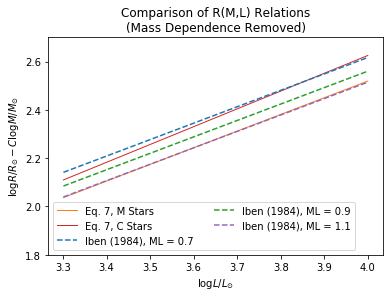

In [364]:
# Plot: log R - mass dependence vs lum.
plot.xlabel(r'$\log L/L_{\odot}$')
plot.ylabel(r'$\log R/R_{\odot}-C\log M/M_{\odot}$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M stars
plot.plot(np.log10(luminosity_grid),np.log10(RMM_Mcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, M Stars')
# Prager et al. 2021, C stars
plot.plot(np.log10(luminosity_grid),np.log10(RCM_Mcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, C Stars')

iben_linestyle = '--'
iben_size = 0
iben_linesize=1
# Iben 1984, ML=0.7
plot.plot(np.log10(luminosity_grid),np.log10(RIben07_Mcorected[0]),color=color_list[0],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.7')
# Iben 1984, ML=0.9
plot.plot(np.log10(luminosity_grid),np.log10(RIben09_Mcorected[0]),color=color_list[2],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.9')
# Iben 1984, ML=1.1
plot.plot(np.log10(luminosity_grid),np.log10(RIben11_Mcorected[0]),color=color_list[4],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 1.1')

plot.ylim(1.8,2.7)
plot.title('Comparison of R(M,L) Relations\n(Mass Dependence Removed)')
plot.legend(ncol=2)
plot.show()
plot.close()

In [298]:
R_M_for_L0 = evolutionary_track( mass_grid, luminosity_grid[0],'M')
R_M_for_L1 = evolutionary_track( mass_grid, luminosity_grid[1],'M')
R_M_for_L2 = evolutionary_track( mass_grid, luminosity_grid[2],'M')
R_M_for_L3 = evolutionary_track( mass_grid, luminosity_grid[3],'M')
R_M_for_L4 = evolutionary_track( mass_grid, luminosity_grid[4],'M')
R_M_L_list = np.asarray([R_M_for_L0,R_M_for_L1,R_M_for_L2,R_M_for_L3,R_M_for_L4])

R_C_for_L0 = evolutionary_track( mass_grid, luminosity_grid[0],'C')
R_C_for_L1 = evolutionary_track( mass_grid, luminosity_grid[1],'C')
R_C_for_L2 = evolutionary_track( mass_grid, luminosity_grid[2],'C')
R_C_for_L3 = evolutionary_track( mass_grid, luminosity_grid[3],'C')
R_C_for_L4 = evolutionary_track( mass_grid, luminosity_grid[4],'C')
R_C_L_list = np.asarray([R_C_for_L0,R_C_for_L1,R_C_for_L2,R_C_for_L3,R_C_for_L4])

RIben_07_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 0.7, 0.003)
RIben_07_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 0.7, 0.003)
RIben_07_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 0.7, 0.003)
RIben_07_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 0.7, 0.003)
RIben_07_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 0.7, 0.003)
RIben_07_L_list = np.asarray([RIben_07_for_L0,RIben_07_for_L1,RIben_07_for_L2,RIben_07_for_L3,RIben_07_for_L4])

RIben_09_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 0.9, 0.003)
RIben_09_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 0.9, 0.003)
RIben_09_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 0.9, 0.003)
RIben_09_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 0.9, 0.003)
RIben_09_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 0.9, 0.003)
RIben_09_L_list = np.asarray([RIben_09_for_L0,RIben_09_for_L1,RIben_09_for_L2,RIben_09_for_L3,RIben_09_for_L4])

RIben_11_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 1.1, 0.003)
RIben_11_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 1.1, 0.003)
RIben_11_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 1.1, 0.003)
RIben_11_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 1.1, 0.003)
RIben_11_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 1.1, 0.003)
RIben_11_L_list = np.asarray([RIben_11_for_L0,RIben_11_for_L1,RIben_11_for_L2,RIben_11_for_L3,RIben_11_for_L4])

In [300]:
RM_L_Correction = np.asarray([0.690*np.log10(luminosity_grid[0]),0.690*np.log10(luminosity_grid[1]),0.690*np.log10(luminosity_grid[2]),
                               0.690*np.log10(luminosity_grid[3]),0.690*np.log10(luminosity_grid[4])])
#print(R_M_L_list)
RML_Lcorrected = 10**(np.log10(R_M_L_list)
                      -np.transpose(np.asarray([RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction,
                                                     RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction])))
print(RML_Lcorrected)

RC_L_Correction = np.asarray([0.737*np.log10(luminosity_grid[0]),0.737*np.log10(luminosity_grid[1]),0.737*np.log10(luminosity_grid[2]),
                               0.737*np.log10(luminosity_grid[3]),0.737*np.log10(luminosity_grid[4])])
#print(R_C_L_list)
RCL_Lcorrected = 10**(np.log10(R_C_L_list)
                      -np.transpose(np.asarray([RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction,
                                                     RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction])))
print(RCL_Lcorrected)


RIben_L_Correction = np.asarray([0.68*np.log10(luminosity_grid[0]),0.68*np.log10(luminosity_grid[1]), 0.68*np.log10(luminosity_grid[2]),
                                 0.68*np.log10(luminosity_grid[3]), 0.68*np.log10(luminosity_grid[4])])
#print(RIben_L_Correction)
#print(RIben_07_L_list)
RIben07_Lcorrected = 10**(np.log10(RIben_07_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben07_Lcorrected)

RIben09_Lcorrected = 10**(np.log10(RIben_09_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben09_Lcorrected)

RIben11_Lcorrected = 10**(np.log10(RIben_11_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben11_Lcorrected)

[[0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]]
[[0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.3862

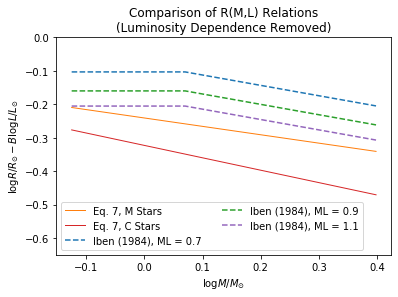

In [365]:
# Plot: log R - lum. dependence vs mass
plot.xlabel(r'$\log M/M_{\odot}$')
plot.ylabel(r'$\log R/R_{\odot}-B\log L/L_{\odot}$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M stars
plot.plot(np.log10(mass_grid),np.log10(RML_Lcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, M Stars')
# Prager et al. 2021, C stars
plot.plot(np.log10(mass_grid),np.log10(RCL_Lcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, C Stars')

iben_linestyle = '--'
iben_size = 0
iben_linesize=1
# Iben 1984, ML=0.7
plot.plot(np.log10(mass_grid),np.log10(RIben07_Lcorrected[0]),color=color_list[0],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.7')
# Iben 1984, ML=0.9
plot.plot(np.log10(mass_grid),np.log10(RIben09_Lcorrected[0]),color=color_list[2],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.9')
# Iben 1984, ML=1.1
plot.plot(np.log10(mass_grid),np.log10(RIben11_Lcorrected[0]),color=color_list[4],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 1.1')


plot.ylim(-0.65,0)
plot.title('Comparison of R(M,L) Relations\n(Luminosity Dependence Removed)')
plot.legend(ncol=2)
plot.show()
plot.close()

In [317]:
P_M0_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,0,'M')
P_M0_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,0,'M')
P_M0_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,0,'M')
P_M0_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,0,'M')
P_M0_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,0,'M')
P_M0_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,0,'M')
P_M0_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,0,'M')
P_M0_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,0,'M')
P_M0_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,0,'M')
P_M0_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,0,'M')
P_M0_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,0,'M')
P_M0_R_list = np.asarray([P_M0_for_R0,P_M0_for_R1,P_M0_for_R2,P_M0_for_R3,
                          P_M0_for_R4,P_M0_for_R5,P_M0_for_R6,P_M0_for_R7,
                          P_M0_for_R8,P_M0_for_R9,P_M0_for_R10])
#print(P_M0_R_list)

P_C0_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,0,spec_type_ID='C')
P_C0_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,0,spec_type_ID='C')
P_C0_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,0,spec_type_ID='C')
P_C0_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,0,spec_type_ID='C')
P_C0_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,0,spec_type_ID='C')
P_C0_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,0,spec_type_ID='C')
P_C0_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,0,spec_type_ID='C')
P_C0_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,0,spec_type_ID='C')
P_C0_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,0,spec_type_ID='C')
P_C0_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,0,spec_type_ID='C')
P_C0_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,0,spec_type_ID='C')
P_C0_R_list = np.asarray([P_C0_for_R0,P_C0_for_R1,P_C0_for_R2,P_C0_for_R3,
                          P_C0_for_R4,P_C0_for_R5,P_C0_for_R6,P_C0_for_R7,
                          P_C0_for_R8,P_C0_for_R9,P_C0_for_R10])
#print(P_C0_R_list)

P_1_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,1)
P_1_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,1)
P_1_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,1)
P_1_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,1)
P_1_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,1)
P_1_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,1)
P_1_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,1)
P_1_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,1)
P_1_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,1)
P_1_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,1)
P_1_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,1)
P_1_R_list = np.asarray([P_1_for_R0,P_1_for_R1,P_1_for_R2,P_1_for_R3,
                         P_1_for_R4,P_1_for_R5,P_1_for_R6,P_1_for_R7,
                         P_1_for_R8,P_1_for_R9,P_1_for_R10 ])
#print(P_1_R_list)

P_OC0_for_R0 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[0],0)
P_OC0_for_R1 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[1],0)
P_OC0_for_R2 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[2],0)
P_OC0_for_R3 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[3],0)
P_OC0_for_R4 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[4],0)
P_OC0_for_R5 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[5],0)
P_OC0_for_R6 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[6],0)
P_OC0_for_R7 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[7],0)
P_OC0_for_R8 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[8],0)
P_OC0_for_R9 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[9],0)
P_OC0_for_R10 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[10],0)
P_OC0_R_list = np.asarray([P_OC0_for_R0,P_OC0_for_R1,P_OC0_for_R2,P_OC0_for_R3,
                           P_OC0_for_R4,P_OC0_for_R5,P_OC0_for_R6,P_OC0_for_R7,
                           P_OC0_for_R8,P_OC0_for_R9,P_OC0_for_R10])
#print(P_OC0_R_list)

P_OC1_for_R0 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[0],1)
P_OC1_for_R1 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[1],1)
P_OC1_for_R2 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[2],1)
P_OC1_for_R3 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[3],1)
P_OC1_for_R4 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[4],1)
P_OC1_for_R5 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[5],1)
P_OC1_for_R6 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[6],1)
P_OC1_for_R7 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[7],1)
P_OC1_for_R8 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[8],1)
P_OC1_for_R9 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[9],1)
P_OC1_for_R10 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[10],1)
P_OC1_R_list = np.asarray([P_OC1_for_R0,P_OC1_for_R1,P_OC1_for_R2,P_OC1_for_R3,
                           P_OC1_for_R4,P_OC1_for_R5,P_OC1_for_R6,P_OC1_for_R7,
                           P_OC1_for_R8,P_OC1_for_R9,P_OC1_for_R10])
#print(P_OC1_R_list)

P_FW_for_R0 = pmr_relation_Fox_Wood( mass_grid, radius_grid[0])
P_FW_for_R1 = pmr_relation_Fox_Wood( mass_grid, radius_grid[1])
P_FW_for_R2 = pmr_relation_Fox_Wood( mass_grid, radius_grid[2])
P_FW_for_R3 = pmr_relation_Fox_Wood( mass_grid, radius_grid[3])
P_FW_for_R4 = pmr_relation_Fox_Wood( mass_grid, radius_grid[4])
P_FW_for_R5 = pmr_relation_Fox_Wood( mass_grid, radius_grid[5])
P_FW_for_R6 = pmr_relation_Fox_Wood( mass_grid, radius_grid[6])
P_FW_for_R7 = pmr_relation_Fox_Wood( mass_grid, radius_grid[7])
P_FW_for_R8 = pmr_relation_Fox_Wood( mass_grid, radius_grid[8])
P_FW_for_R9 = pmr_relation_Fox_Wood( mass_grid, radius_grid[9])
P_FW_for_R10 = pmr_relation_Fox_Wood( mass_grid, radius_grid[10])
P_FW_R_list = np.asarray([P_FW_for_R0,P_FW_for_R1,P_FW_for_R2,P_FW_for_R3,
                          P_FW_for_R4,P_FW_for_R5,P_FW_for_R6,P_FW_for_R7,
                          P_FW_for_R8,P_FW_for_R9,P_FW_for_R10])

In [318]:
print(P_M0_R_list)

[[  52.60664506   42.03038843   37.06123268   35.3145935    30.63211638
    27.16096013   24.47370952   22.32495556   20.56319571]
 [ 119.66787746   95.60935442   84.30568126   80.33248352   69.68093755
    61.78486473   55.67199483   50.78407952   46.77648577]
 [ 214.40179013  171.29757105  151.04545484  143.9269137   124.84317484
   110.69625268   99.7441887    90.98680273   83.80663632]
 [ 337.02723974  269.26989513  237.43473732  226.2448015   196.24626544
   174.0081203   156.79210784  143.02600252  131.73919534]
 [ 487.71418744  389.66211814  343.59326585  327.40024103  283.98917536
   251.80821901  226.8948217   206.9738062   190.64059824]
 [ 666.60187643  532.58548924  469.61913687  447.48670561  388.15298398
   344.16844049  310.11710915  282.88930513  260.56527324]
 [ 873.80838602  698.13434859  615.59553692  586.58346131  508.80644723
   451.1497494   406.51390313  370.82260923  341.55937586]
 [1109.43629939  886.39065563  781.59473556  744.75937175  646.00929786
   572.8051

In [341]:
print(len(radius_grid))
print(len(mass_grid))
print(np.shape(P_M0_R_list))

11
9
(11, 9)


In [336]:
multiplier = 2.2027
PM0_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
PM0_Rcorrected = 10**(np.log10(P_M0_R_list)
                      -np.transpose(np.asarray([PM0_Rad_Correction,PM0_Rad_Correction,PM0_Rad_Correction,
                                                PM0_Rad_Correction,PM0_Rad_Correction,PM0_Rad_Correction,
                                                PM0_Rad_Correction,PM0_Rad_Correction,PM0_Rad_Correction])))


multiplier=2.043
PC0_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
PC0_Rcorrected = 10**(np.log10(P_C0_R_list)
                      -np.transpose(np.asarray([PC0_Rad_Correction,PC0_Rad_Correction,PC0_Rad_Correction,
                                                PC0_Rad_Correction,PC0_Rad_Correction,PC0_Rad_Correction,
                                                PC0_Rad_Correction,PC0_Rad_Correction,PC0_Rad_Correction])))

multiplier = 1.570
P1_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
P1_Rcorrected = 10**(np.log10(P_1_R_list)
                      -np.transpose(np.asarray([P1_Rad_Correction,P1_Rad_Correction,P1_Rad_Correction,
                                                P1_Rad_Correction,P1_Rad_Correction,P1_Rad_Correction,
                                                P1_Rad_Correction,P1_Rad_Correction,P1_Rad_Correction])))

multiplier = 1.86
POC0_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
POC0_Rcorrected = 10**(np.log10(P_OC0_R_list)
                      -np.transpose(np.asarray([POC0_Rad_Correction,POC0_Rad_Correction,POC0_Rad_Correction,
                                                POC0_Rad_Correction,POC0_Rad_Correction,POC0_Rad_Correction,
                                                POC0_Rad_Correction,POC0_Rad_Correction,POC0_Rad_Correction])))

multiplier = 1.59
POC1_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
POC1_Rcorrected = 10**(np.log10(P_OC1_R_list)
                      -np.transpose(np.asarray([POC1_Rad_Correction,POC1_Rad_Correction,POC1_Rad_Correction,
                                                POC1_Rad_Correction,POC1_Rad_Correction,POC1_Rad_Correction,
                                                POC1_Rad_Correction,POC1_Rad_Correction,POC1_Rad_Correction])))

multiplier = 2
PFW_Rad_Correction = np.asarray([multiplier*np.log10(radius_grid[0]),multiplier*np.log10(radius_grid[1]),multiplier*np.log10(radius_grid[2]),
                               multiplier*np.log10(radius_grid[3]),multiplier*np.log10(radius_grid[4]),multiplier*np.log10(radius_grid[5]),
                               multiplier*np.log10(radius_grid[6]),multiplier*np.log10(radius_grid[7]),multiplier*np.log10(radius_grid[8]),
                                multiplier*np.log10(radius_grid[9]),multiplier*np.log10(radius_grid[10])])
PFW_Rcorrected = 10**(np.log10(P_FW_R_list)
                      -np.transpose(np.asarray([PFW_Rad_Correction,PFW_Rad_Correction,PFW_Rad_Correction,
                                                PFW_Rad_Correction,PFW_Rad_Correction,PFW_Rad_Correction,
                                                PFW_Rad_Correction,PFW_Rad_Correction,PFW_Rad_Correction])))

In [ ]:
color_list = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]
symbol_list = ['o','v','^','s','x']

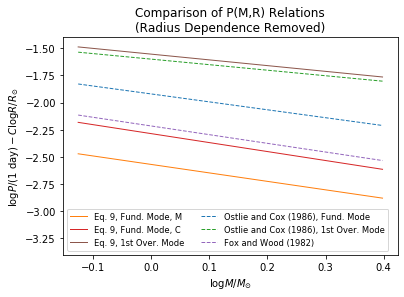

In [363]:
# Plot: log P - rad. dependence vs mass
plot.xlabel(r'$\log M/M_{\odot}$')
plot.ylabel(r'$\log P/(\mathrm{1\ day})-C\log R/R_{\odot}$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M0 stars
plot.plot(np.log10(mass_grid),np.log10(PM0_Rcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, M')
# Prager et al. 2021, C0 stars
plot.plot(np.log10(mass_grid),np.log10(PC0_Rcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, C')
# Trabuchhi et al., First Overtone stars
plot.plot(np.log10(mass_grid),np.log10(P1_Rcorrected[0]),color=color_list[5],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, 1st Over. Mode')

oc_linestyle = '--'
oc_size = 0
oc_linesize = 1
# Ostlie and Cox, 1984 Fundamental Mode
plot.plot(np.log10(mass_grid),np.log10(POC0_Rcorrected[0]),color=color_list[0],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), Fund. Mode')
plot.plot(np.log10(mass_grid),np.log10(POC1_Rcorrected[0]),color=color_list[2],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), 1st Over. Mode')
plot.plot(np.log10(mass_grid),np.log10(PFW_Rcorrected[0]),color=color_list[4],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Fox and Wood (1982)')


plot.ylim(-3.4,-1.4)
plot.title('Comparison of P(M,R) Relations\n(Radius Dependence Removed)')
plot.legend(ncol=2,fontsize='small')
plot.show()
plot.close()

In [346]:
P_M0_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,0,'M')
P_M0_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,0,'M')
P_M0_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,0,'M')
P_M0_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,0,'M')
P_M0_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,0,'M')
P_M0_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,0,'M')
P_M0_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,0,'M')
P_M0_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,0,'M')
P_M0_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,0,'M')
P_M0_M_list = np.asarray([P_M0_for_M0,P_M0_for_M1,P_M0_for_M2,P_M0_for_M3,P_M0_for_M4,P_M0_for_M5,P_M0_for_M6,P_M0_for_M7,P_M0_for_M7])
#print(P_M0_R_list)

P_C0_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,0,spec_type_ID='C')
P_C0_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,0,spec_type_ID='C')
P_C0_M_list = np.asarray([P_C0_for_M0,P_C0_for_M1,P_C0_for_M2,P_C0_for_M3,P_C0_for_M4,P_C0_for_M5,P_C0_for_M6,P_C0_for_M7,P_C0_for_M8])
#print(P_C0_R_list)

P_1_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,1)
P_1_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,1)
P_1_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,1)
P_1_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,1)
P_1_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,1)
P_1_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,1)
P_1_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,1)
P_1_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,1)
P_1_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,1)
P_1_M_list = np.asarray([P_1_for_M0,P_1_for_M1,P_1_for_M2,P_1_for_M3,P_1_for_M4,P_1_for_M5,P_1_for_M6,P_1_for_M7,P_1_for_M8])
#print(P_1_R_list)

P_OC0_for_M0 = pmr_relation_Ostlie_Cox( mass_grid[0], radius_grid,0)
P_OC0_for_M1 = pmr_relation_Ostlie_Cox( mass_grid[1], radius_grid,0)
P_OC0_for_M2 = pmr_relation_Ostlie_Cox( mass_grid[2], radius_grid,0)
P_OC0_for_M3 = pmr_relation_Ostlie_Cox( mass_grid[3], radius_grid,0)
P_OC0_for_M4 = pmr_relation_Ostlie_Cox( mass_grid[4], radius_grid,0)
P_OC0_for_M5 = pmr_relation_Ostlie_Cox( mass_grid[5], radius_grid,0)
P_OC0_for_M6 = pmr_relation_Ostlie_Cox( mass_grid[6], radius_grid,0)
P_OC0_for_M7 = pmr_relation_Ostlie_Cox( mass_grid[7], radius_grid,0)
P_OC0_for_M8 = pmr_relation_Ostlie_Cox( mass_grid[8], radius_grid,0)
P_OC0_M_list = np.asarray([P_OC0_for_M0,P_OC0_for_M1,P_OC0_for_M2,P_OC0_for_M3,P_OC0_for_M4,P_OC0_for_M5,P_OC0_for_M6,P_OC0_for_M7,P_OC0_for_M8])
#print(P_OC0_R_list)

P_OC1_for_M0 = pmr_relation_Ostlie_Cox( mass_grid[0], radius_grid,1)
P_OC1_for_M1 = pmr_relation_Ostlie_Cox( mass_grid[1], radius_grid,1)
P_OC1_for_M2 = pmr_relation_Ostlie_Cox( mass_grid[2], radius_grid,1)
P_OC1_for_M3 = pmr_relation_Ostlie_Cox( mass_grid[3], radius_grid,1)
P_OC1_for_M4 = pmr_relation_Ostlie_Cox( mass_grid[4], radius_grid,1)
P_OC1_for_M5 = pmr_relation_Ostlie_Cox( mass_grid[5], radius_grid,1)
P_OC1_for_M6 = pmr_relation_Ostlie_Cox( mass_grid[6], radius_grid,1)
P_OC1_for_M7 = pmr_relation_Ostlie_Cox( mass_grid[7], radius_grid,1)
P_OC1_for_M8 = pmr_relation_Ostlie_Cox( mass_grid[8], radius_grid,1)
P_OC1_M_list = np.asarray([P_OC1_for_M0,P_OC1_for_M1,P_OC1_for_M2,P_OC1_for_M3,P_OC1_for_M4,P_OC1_for_M5,P_OC1_for_M6,P_OC1_for_M7,P_OC1_for_M8])
#print(P_OC1_M_list)

P_FW_for_M0 = pmr_relation_Fox_Wood( mass_grid[0], radius_grid)
P_FW_for_M1 = pmr_relation_Fox_Wood( mass_grid[1], radius_grid)
P_FW_for_M2 = pmr_relation_Fox_Wood( mass_grid[2], radius_grid)
P_FW_for_M3 = pmr_relation_Fox_Wood( mass_grid[3], radius_grid)
P_FW_for_M4 = pmr_relation_Fox_Wood( mass_grid[4], radius_grid)
P_FW_for_M5 = pmr_relation_Fox_Wood( mass_grid[5], radius_grid)
P_FW_for_M6 = pmr_relation_Fox_Wood( mass_grid[6], radius_grid)
P_FW_for_M7 = pmr_relation_Fox_Wood( mass_grid[7], radius_grid)
P_FW_for_M8 = pmr_relation_Fox_Wood( mass_grid[8], radius_grid)
P_FW_M_list = np.asarray([P_FW_for_M0,P_FW_for_M1,P_FW_for_M2,P_FW_for_M3,P_FW_for_M4,P_FW_for_M5,P_FW_for_M6,P_FW_for_M7,P_FW_for_M8])

In [347]:
len(mass_grid)

9

In [359]:
multiplier = -0.780
PM0_M_Correction = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
PM0_Mcorrected = 10**(np.log10(P_M0_M_list)
                      -np.transpose(np.asarray([PM0_M_Correction,PM0_M_Correction,PM0_M_Correction,PM0_M_Correction,
                                                PM0_M_Correction,PM0_M_Correction,PM0_M_Correction,PM0_M_Correction,
                                                PM0_M_Correction,PM0_M_Correction,PM0_M_Correction])))
print(PM0_Mcorrected[0])

multiplier = -0.826
PC0_M_Correction  = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
PC0_Mcorrected = 10**(np.log10(P_C0_M_list)
                      -np.transpose(np.asarray([PC0_M_Correction,PC0_M_Correction,PC0_M_Correction,PC0_M_Correction,
                                                PC0_M_Correction,PC0_M_Correction,PC0_M_Correction,PC0_M_Correction,
                                                PC0_M_Correction,PC0_M_Correction,PC0_M_Correction])))
print(PC0_Mcorrected[0])
multiplier = -0.529
P1_M_Correction = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
P1_Mcorrected = 10**(np.log10(P_1_M_list)
                      -np.transpose(np.asarray([P1_M_Correction,P1_M_Correction,P1_M_Correction,P1_M_Correction,
                                                P1_M_Correction,P1_M_Correction,P1_M_Correction,P1_M_Correction,
                                                P1_M_Correction,P1_M_Correction,P1_M_Correction])))
print(P1_Mcorrected[0])
multiplier = -0.73
POC0_M_Correction = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
POC0_Mcorrected = 10**(np.log10(P_OC0_M_list)
                      -np.transpose(np.asarray([POC0_M_Correction,POC0_M_Correction,POC0_M_Correction,POC0_M_Correction,
                                                POC0_M_Correction,POC0_M_Correction,POC0_M_Correction,POC0_M_Correction,
                                                POC0_M_Correction,POC0_M_Correction,POC0_M_Correction])))
print(POC0_Mcorrected[0])
multiplier = -0.51
POC1_M_Correction = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
POC1_Mcorrected = 10**(np.log10(P_OC1_M_list)
                      -np.transpose(np.asarray([POC1_M_Correction,POC1_M_Correction,POC1_M_Correction,POC1_M_Correction,
                                                POC1_M_Correction,POC1_M_Correction,POC1_M_Correction,POC1_M_Correction,
                                                POC1_M_Correction,POC1_M_Correction,POC1_M_Correction])))
print(POC1_Mcorrected[0])
multiplier = -0.8
PFW_M_Correction = np.asarray([multiplier*np.log10(mass_grid[0]),multiplier*np.log10(mass_grid[1]),multiplier*np.log10(mass_grid[2]),
                               multiplier*np.log10(mass_grid[3]),multiplier*np.log10(mass_grid[4]),multiplier*np.log10(mass_grid[5]),
                               multiplier*np.log10(mass_grid[6]),multiplier*np.log10(mass_grid[7]),multiplier*np.log10(mass_grid[8])])
PFW_Mcorrected = 10**(np.log10(P_FW_M_list)
                      -np.transpose(np.asarray([PFW_M_Correction,PFW_M_Correction,PFW_M_Correction,PFW_M_Correction,
                                                PFW_M_Correction,PFW_M_Correction,PFW_M_Correction,PFW_M_Correction,
                                                PFW_M_Correction,PFW_M_Correction,PFW_M_Correction])))
print(PFW_Mcorrected[0])

[  42.03280678   95.6148556   171.30742718  269.2853884   389.68453854
  532.61613318  698.17451789  886.44165683 1097.49004649 1331.38470357
 1588.18458312]
[  40.08785727   91.78406448  165.20269376  260.61792408  378.24358124
  518.25542635  680.8029136   866.01618586 1074.01058667 1304.88974499
 1558.74778001]
[ 27.15509207  51.32329803  80.62474847 114.45034158 152.38129129
 194.10561972 239.37867897 288.00161705 339.8084595  394.65781043
 452.42723728]
[  41.66269658   88.56805708  151.23878082  229.04235052  321.50883339
  428.2663364   549.0083625   683.47502795  831.44128191  992.70904345
 1167.10169964]
[ 26.66324967  50.80403204  80.26953968 114.45577044 152.94520796
 195.42551712 241.65092703 291.42108864 344.56835236 400.94957329
 460.44055362]
[  39.04   87.84  156.16  244.    351.36  478.24  624.64  790.56  976.
 1180.96 1405.44]


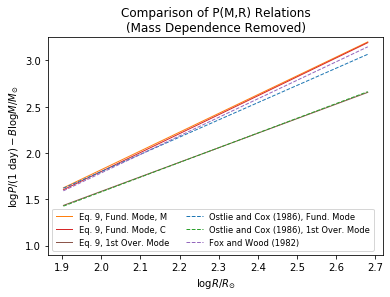

In [362]:
# Plot: log P - mass dependence vs rad.
plot.xlabel(r'$\log R/R_{\odot}$')
plot.ylabel(r'$\log P/(\mathrm{1\ day})-B\log M/M_{\odot}$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M0 stars
plot.plot(np.log10(radius_grid),np.log10(PM0_Mcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, M')
# Prager et al. 2021, C0 stars
plot.plot(np.log10(radius_grid),np.log10(PC0_Mcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, C')
# Trabuchhi et al., First Overtone stars
plot.plot(np.log10(radius_grid),np.log10(P1_Mcorrected[0]),color=color_list[5],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, 1st Over. Mode')

oc_linestyle = '--'
oc_size = 0
oc_linesize = 1
# Ostlie and Cox, 1984 Fundamental Mode
plot.plot(np.log10(radius_grid),np.log10(POC0_Mcorrected[0]),color=color_list[0],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), Fund. Mode')
plot.plot(np.log10(radius_grid),np.log10(POC1_Mcorrected[0]),color=color_list[2],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), 1st Over. Mode')
plot.plot(np.log10(radius_grid),np.log10(PFW_Mcorrected[0]),color=color_list[4],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Fox and Wood (1982)')


plot.ylim(0.9,3.25)
plot.title('Comparison of P(M,R) Relations\n(Mass Dependence Removed)')
plot.legend(ncol=2,fontsize='small')
plot.show()
plot.close()